# Shor's Algorithm — from period finding to breaking RSA

This notebook is the hands-on companion to the lesson *"RSA and Shor's Algorithm"*.
It walks the full pipeline end to end:

1. **The problem** — order (period) finding of $f(x)=a^x \bmod N$.
2. **The number theory** — why finding the order $r$ lets us factor $N$.
3. **The classical part** — reductions, `gcd`, and (for contrast) brute-force order finding.
4. **The quantum part** — Quantum Phase Estimation (QPE) of the modular-multiplication operator $U$.
5. **Continued fractions** — turning a measured phase $\phi \approx s/r$ into the order $r$.
6. **A complete, robust `shor_factor(N)`** that loops until it succeeds.
7. **Breaking a (toy) RSA key** with the order we recovered — closing the loop with the lesson.
8. **Resource reality check** — why RSA-2048 is still safe *today*.

> Backend: this is the **IBM / Aer — the `../IQM` folder has the IQM Garnet/Emerald edition** edition.


In [1]:
# pylint: disable=invalid-name
import numpy as np                     # numerical arrays (np.arange, np.pi) and random numbers
import pandas as pd                    # tables (DataFrame) for printing results
import matplotlib.pyplot as plt        # plotting
from math import gcd                   # greatest common divisor (Euclid's algorithm)
from fractions import Fraction         # exact rational numbers; .limit_denominator() = continued fractions

from qiskit import QuantumCircuit                       # the object we build circuits with
from qiskit.visualization import plot_histogram         # bar chart of measurement counts
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler: circuit -> backend gates
from qiskit_aer import AerSimulator                     # local classical simulator of a quantum computer
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

import qiskit; print("qiskit", qiskit.__version__)


qiskit 2.1.2


## 1. The problem: period (order) finding

Fix two integers $N$ and $a$ with $1 < a < N$ and $\gcd(a,N)=1$. The function

$$ f(x) = a^x \bmod N $$

is **periodic**: there is a smallest positive integer $r$, the **order** of $a$ modulo $N$, with

$$ a^r \equiv 1 \pmod N . $$

Then $f(x+r)=f(x)$ for all $x$. The order $r$ exists because $a$ is invertible modulo $N$
(a consequence of $\gcd(a,N)=1$), so the powers $a^0,a^1,a^2,\dots$ must eventually cycle.

Let's see the period for $a=3,\ N=35$ (the dotted lines only guide the eye).

Order of 3 mod 35 is r = 12   (check: 3^12 mod 35 = 1)


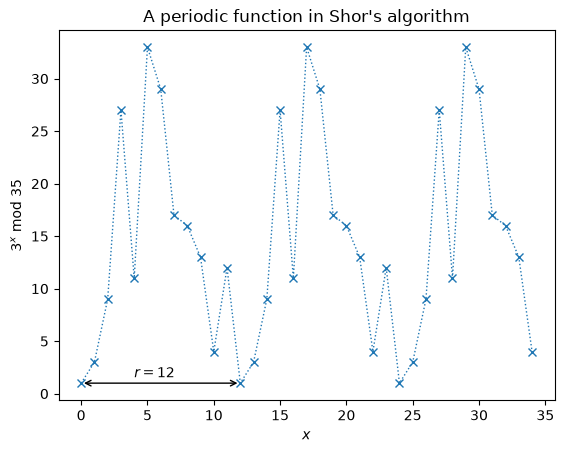

In [2]:
N = 35          # the number we pretend to factor
a = 3           # the base, coprime with N

xvals = np.arange(N)                             # NumPy array 0, 1, ..., N-1
yvals = [pow(a, int(x), N) for x in xvals]       # list comprehension; pow(a, x, N) = a**x mod N, computed efficiently

fig, ax = plt.subplots()                         # one matplotlib figure with one set of axes
ax.plot(xvals, yvals, linewidth=1, linestyle='dotted', marker='x')
ax.set(xlabel='$x$', ylabel=f'${a}^x$ mod ${N}$',               # f-string: {a} and {N} are replaced by their values
       title="A periodic function in Shor's algorithm")
try:
    r = yvals[1:].index(1) + 1                   # first x > 0 with a^x mod N == 1, i.e. the order r
    plt.annotate('', xy=(0, 1), xytext=(r, 1), arrowprops=dict(arrowstyle='<->'))   # double arrow of length r
    plt.annotate(f'$r={r}$', xy=(r/3, 1.5))
    print(f"Order of {a} mod {N} is r = {r}   (check: {a}^{r} mod {N} = {pow(a, r, N)})")
except ValueError:                               # list.index() raises ValueError if the value 1 never appears
    print('Could not find period: check that a < N and gcd(a, N) = 1.')


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `pow(a, x, N)` | modular exponentiation in one call: Python squares and reduces as it goes, so `pow(3, 10**6, 35)` is instant while `3**10**6 % 35` would first build a 477 000-digit number |
| `[... for x in xvals]` | a list comprehension: one value of aˣ mod N per x, in order |
| `yvals[1:].index(1) + 1` | the first x ≥ 1 with aˣ ≡ 1: the order r by definition; the `try/except` catches the case where 1 never shows up (gcd(a, N) ≠ 1) |
| `ax.plot(..., marker='x')`, `plt.annotate` | the crosses are the function, the arrow spans one period |

</details>


## 2. Why the order lets us factor $N$

This is the classical reduction that makes Shor's algorithm useful. Suppose we have found the
order $r$ of $a$ modulo $N$, and suppose **$r$ is even**. Write $x = a^{r/2} \bmod N$. Then

$$ x^2 = a^{r} \equiv 1 \pmod N \quad\Longrightarrow\quad x^2 - 1 \equiv 0 \pmod N
   \quad\Longrightarrow\quad (x-1)(x+1) \equiv 0 \pmod N . $$

So $N \mid (x-1)(x+1)$. If in addition **$x \not\equiv -1 \pmod N$** (and clearly $x\not\equiv 1$,
since $r$ is the *smallest* exponent giving $1$), then neither factor is a multiple of $N$ on its own.
Hence $N$ must split its prime factors between $x-1$ and $x+1$, and

$$ \gcd(x-1,\, N) \quad\text{and}\quad \gcd(x+1,\, N) $$

are **non-trivial factors of $N$**. Computing a gcd is cheap (Euclid's algorithm).

**The gamble.** We need $r$ even *and* $a^{r/2}\not\equiv -1$. For a random $a$ coprime to a
(non-prime-power) odd $N$, a classic theorem guarantees this happens with probability
$\ge 1 - 2^{-k}$ where $k$ is the number of distinct odd prime factors of $N$ — so at least
$1/2$, usually $\ge 3/4$. If the gamble fails, we simply pick a new random $a$ and try again.

Everything above is classical. The *only* hard step is computing $r$ — and **that** is what the
quantum computer does exponentially faster than any known classical method.

In [3]:
def factors_from_order(a, r, N):
    """Given the order r of a mod N, try to extract non-trivial factors of N.
    Returns a sorted list of the non-trivial factors found (possibly empty)."""
    if r % 2 != 0:                     # % = remainder; r % 2 != 0 means r is odd
        return []                      # r odd: cannot use the (x-1)(x+1) split
    x = pow(a, r // 2, N)              # // = integer division; pow(a, k, N) = a^k mod N
    if x == N - 1:                     # N - 1 is the same as -1 modulo N
        return []                      # a^{r/2} == -1 mod N: unlucky, retry with new a
    cands = [gcd(x - 1, N), gcd(x + 1, N)]
    # set comprehension {...} removes duplicates; keep only the non-trivial divisors of N
    return sorted({c for c in cands if 1 < c < N and N % c == 0})

# Sanity check with the a=3, N=35 example above (r = 12):
print("factors of 35 from a=3, r=12:", factors_from_order(3, 12, 35))


factors of 35 from a=3, r=12: [5, 7]


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `r % 2 != 0` | odd order: a^{r/2} is not an integer power, and the trick needs x² = aʳ |
| `pow(a, r // 2, N)` | x = a^{r/2} mod N, a square root of 1 modulo N |
| `x == N - 1` | x ≡ −1 (mod N): the trivial root; x + 1 is a multiple of N and both gcds are trivial |
| `gcd(x - 1, N), gcd(x + 1, N)` | Euclid's algorithm: N must split its primes between the two factors of x² − 1 |
| `{c for c in cands if ...}` | a set comprehension keeps only non-trivial divisors and drops duplicates; `sorted` turns the set back into a list |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**By hand, the two examples of this notebook.**

*a = 7, N = 15.* The powers of 7 mod 15 are $7, 49 \to 4, 28 \to 13, 91 \to 1$, so $r = 4$ (even ✓). Then $x = 7^{2} = 49 \equiv 4$, which is neither $1$ nor $14 \equiv -1$ ✓, and

$$\gcd(x-1, N) = \gcd(3, 15) = 3, \qquad \gcd(x+1, N) = \gcd(5, 15) = 5 .$$

*a = 3, N = 35* (the plot above): $r = 12$, $x = 3^{6} = 729 = 20\cdot 35 + 29 \equiv 29$, and $\gcd(28, 35) = 7$, $\gcd(30, 35) = 5$ ✓.

*A failure.* $a = 14 \equiv -1 \pmod{15}$: $r = 2$ is even, but $x = 14 \equiv -1$, the excluded case — $\gcd(13, 15) = \gcd(15, 15)$ give $1$ and $15$. The loop in Section 6 simply draws another $a$.

*Why it must work when it works.* $N \mid (x-1)(x+1)$ with $N \nmid (x-1)$ and $N \nmid (x+1)$: since $N = pq$, each prime divides one of the two factors, and they cannot both divide the same one (that factor would then be a multiple of $N$). So $p$ sits in one gcd and $q$ in the other.

</details>


## 3. The classical wrapper (and brute-force order finding for contrast)

A real factoring routine first removes the *easy* cases before ever calling the quantum
subroutine:

* $N$ even $\Rightarrow$ factor $2$.
* $N = c^k$ a **perfect power** $\Rightarrow$ factor $c$ (checkable classically in polynomial time).
* a randomly chosen $a$ that already shares a factor with $N$ ($\gcd(a,N)>1$) is a lucky hit.

Only when none of these apply do we invoke order finding. To *see* what the quantum step
computes, here is a **brute-force** classical order finder — correct but exponentially slow,
exactly the bottleneck Shor removes.

In [4]:
def classical_order(a, N):
    """Smallest r>0 with a^r = 1 (mod N), found by brute force. O(r) — slow on purpose."""
    assert gcd(a, N) == 1, "a and N must be coprime"   # assert: stop with this message if the condition is False
    r, val = 1, a % N                                   # tuple assignment: r = 1 and val = a mod N in one line
    while val != 1:                                     # keep multiplying by a until we are back at 1
        val = (val * a) % N
        r += 1                                          # same as r = r + 1
    return r

def is_perfect_power(N):
    """If N = c**k for integers c>=2, k>=2, return (c, k); else None."""
    for k in range(2, N.bit_length() + 1):             # N.bit_length() = number of binary digits of N
        c = round(N ** (1.0 / k))                      # candidate k-th root (floating point, so check the neighbours too)
        for cc in (c - 1, c, c + 1):
            if cc >= 2 and cc ** k == N:               # ** = exponentiation (exact for integers)
                return cc, k                           # returns a tuple (c, k)
    return None

print("classical order of 7 mod 15 :", classical_order(7, 15))   # expect 4
print("is 27 a perfect power?      :", is_perfect_power(27))      # (3, 3)
print("is 15 a perfect power?      :", is_perfect_power(15))      # None


classical order of 7 mod 15 : 4
is 27 a perfect power?      : (3, 3)
is 15 a perfect power?      : None


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `assert cond, msg` | a guard: Python stops with `msg` if the condition is False |
| `r, val = 1, a % N` | tuple assignment: two variables set in one line |
| `while val != 1: val = (val * a) % N` | the brute force: multiply by a until the cycle closes — r multiplications, i.e. exponential in the number of digits of N |
| `N.bit_length()` | number of binary digits of N: the largest k for which cᵏ = N with c ≥ 2 is possible |
| `round(N ** (1.0 / k))` | a floating-point k-th root, then an exact integer check on the three nearest candidates |

</details>


## 4. The quantum part: order finding by Quantum Phase Estimation

Define the unitary modular-multiplication operator

$$ U\,|y\rangle = |a y \bmod N\rangle . $$

Its eigenstates (for $0\le s\le r-1$) are

$$ |u_s\rangle = \frac{1}{\sqrt r}\sum_{k=0}^{r-1} e^{-2\pi i s k / r}\,|a^k \bmod N\rangle,
   \qquad U|u_s\rangle = e^{2\pi i\, s/r}\,|u_s\rangle . $$

The eigenphase is $s/r$ — it **contains the order $r$ we want**. Two facts make this usable:

* The easy-to-prepare state $|1\rangle$ is an equal superposition of all the $|u_s\rangle$:
  $\frac{1}{\sqrt r}\sum_{s=0}^{r-1}|u_s\rangle = |1\rangle$.
* So running **QPE** on $U$ with the register initialised to $|1\rangle$ measures a phase
  $\phi \approx s/r$ for a uniformly random $s\in\{0,\dots,r-1\}$.

We then recover $r$ from $\phi$ with continued fractions (Section 5).

Below, `c_amod15` provides the controlled-$U^{2^q}$ gates for the special case $N=15$ (the standard
small demonstration). Note the classical/quantum division of labour: the number $a^{2^q}\bmod 15$
is computed *classically* by repeated squaring, and the quantum circuit only performs one
controlled multiplication by it. Repeating $U$ literally $2^q$ times would blow the circuit up by
a factor of about 100 for no gain. `qft_dagger` is the inverse QFT that reads out the phase.

In [5]:
def c_amod15(a, power):
    """Controlled-U^power, where U|y> = |a*y mod 15>.

    Shor's algorithm never applies U `power` times in a row: the number a^power mod 15
    is first computed CLASSICALLY by repeated squaring (cheap, O(log power)), and the
    circuit then performs a single multiplication by that number.  For N = 15 every
    a^power mod 15 is again one of {1, 2, 4, 7, 8, 11, 13}, and multiplication by each of
    them is just a permutation of the 4 work qubits (swaps, plus X gates for 7, 11, 13).
    This keeps the circuit ~100x smaller than naively repeating U.
    """
    if a not in [2, 4, 7, 8, 11, 13]:
        raise ValueError("'a' must be 2, 4, 7, 8, 11 or 13")   # raise = abort with an error message
    a_eff = pow(a, power, 15)             # classical modular exponentiation: a^power mod 15
    U = QuantumCircuit(4)                 # a 4-qubit circuit (no classical bits): the work register
    # Qiskit syntax: U.swap(i, j) exchanges qubits i and j; U.x(q) applies a NOT (Pauli X) to qubit q.
    # Qubit indices start at 0; qubit 0 is the least significant bit of the number stored in the register.
    if a_eff in [2, 13]:
        U.swap(2, 3); U.swap(1, 2); U.swap(0, 1)     # ';' separates several statements on one line
    if a_eff in [7, 8]:
        U.swap(0, 1); U.swap(1, 2); U.swap(2, 3)
    if a_eff in [4, 11]:
        U.swap(1, 3); U.swap(0, 2)
    if a_eff in [7, 11, 13]:
        for q in range(4):                           # range(4) = 0, 1, 2, 3
            U.x(q)
    # (a_eff == 1 -> U is the identity: the controlled gate does nothing, as it should)
    U = U.to_gate()                       # pack the whole circuit into a single reusable Gate object
    U.name = f"{a}^{power} mod 15"        # the label shown in circuit drawings
    return U.control()                    # .control() adds ONE control qubit -> controlled-U (a ControlledGate)


def qft_dagger(n):
    """Inverse QFT on the first n qubits."""
    qc = QuantumCircuit(n)
    for qubit in range(n // 2):                      # reverse the qubit order with swaps
        qc.swap(qubit, n - qubit - 1)
    for j in range(n):
        for m in range(j):
            qc.cp(-np.pi / float(2 ** (j - m)), m, j)   # qc.cp(theta, control, target): controlled phase gate
        qc.h(j)                                      # Hadamard on qubit j
    qc.name = "QFT†"
    return qc                                        # a QuantumCircuit; qc.append(...) below uses it as a sub-circuit


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumCircuit(4)` | 4 qubits, no classical bits: the work register that stores y ∈ {0, …, 15} |
| `U.swap(i, j)`, `U.x(q)` | gates are methods of the circuit; the swaps permute the bits of y (a cyclic shift = ×2, ×4, ×8 mod 15, because 16 ≡ 1), the X gates complement them (y → 15 − y); 7, 11, 13 = 15 − 8, 15 − 4, 15 − 2 need both |
| `pow(a, power, 15)` | the classical shortcut: a^power mod 15 is computed before the gate is built, so power = 128 costs the same as power = 1 |
| `U.to_gate()`, `U.name = ...`, `U.control()` | circuit → gate → controlled gate: the box in the drawings, with one extra control wire |
| `qc.cp(theta, m, j)` | the controlled-phase gate with angle −π/2^{j−m}: QFT† is swaps + Hadamards + these |
| `qc.name = "QFT†"` | the label shown in drawings; the circuit is appended as a single box |

</details>


**Visualising the building blocks.** `circuit.draw('mpl')` renders a circuit with matplotlib
(the plain `draw()` gives ASCII art). A `Gate` object has no `draw()`: `c_amod15(...)` returns a
*controlled* gate, so we look at `base_gate.definition`, the circuit of $U$ itself without the control.
`decompose()` expands composite gates by one level, which is how you see what a controlled
multiplication really costs: every controlled SWAP becomes Toffoli (`ccx`) and CNOT (`cx`) gates.
When a cell must show more than one figure, wrap all but the last in `display(...)`.


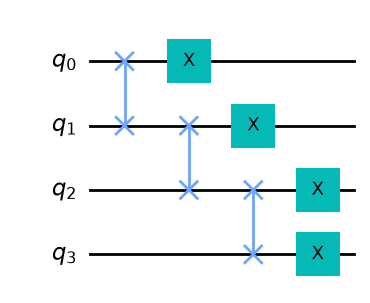

↑ U = multiplication by 7 mod 15: three swaps (a cyclic shift of the 4 bits = ×8) and four X gates (complement = 15 − y), i.e. 7y = 15 − 8y mod 15


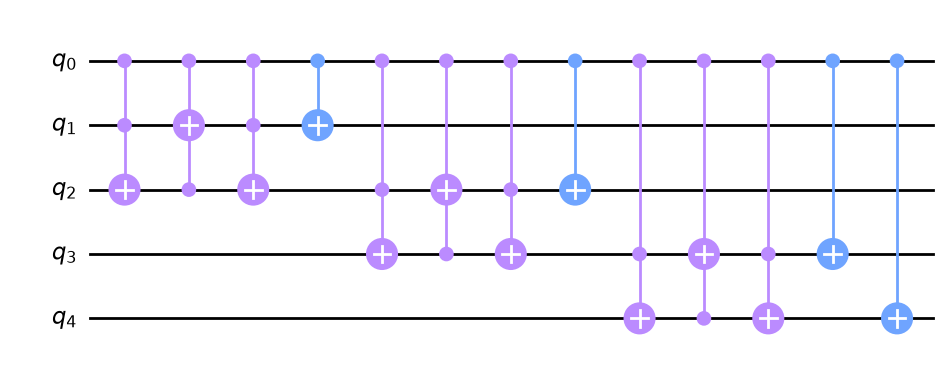

↑ controlled-U after decompose(): every controlled SWAP became Toffoli (ccx) + CNOT gates — {'ccx': 9, 'cx': 4}


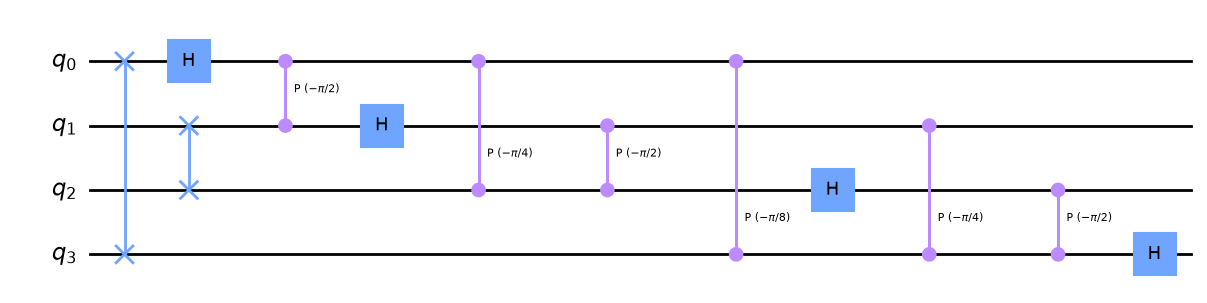

↑ QFT† on 4 qubits: the swaps reverse the qubit order, then Hadamards interleaved with controlled phases of −π/2, −π/4, −π/8


In [6]:
# U for a = 7, power = 1: multiplication by 7 mod 15 on the 4-qubit work register
U7 = c_amod15(7, 1).base_gate.definition          # .base_gate = the gate without its control; .definition = the circuit it was built from
display(draw(U7)); print("↑ U = multiplication by 7 mod 15: three swaps (a cyclic shift of the 4 bits = ×8) and four X gates (complement = 15 − y), i.e. 7y = 15 − 8y mod 15")

# The controlled version placed in a 5-qubit circuit (qubit 0 = control), expanded one level:
cU = QuantumCircuit(5)
cU.append(c_amod15(7, 1), [0, 1, 2, 3, 4])        # append(gate, qubits): control qubit first, then the 4 work qubits
display(draw(cU.decompose())); print(f"↑ controlled-U after decompose(): every controlled SWAP became Toffoli (ccx) + CNOT gates — {dict(cU.decompose().count_ops())}")

# The inverse QFT on 4 qubits
display(draw(qft_dagger(4))); print("↑ QFT† on 4 qubits: the swaps reverse the qubit order, then Hadamards interleaved with controlled phases of −π/2, −π/4, −π/8")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `gate.base_gate.definition` | a controlled gate remembers the gate it controls (`base_gate`); every custom gate remembers the circuit it was built from (`definition`) |
| `cU.append(gate, [0, 1, 2, 3, 4])` | place a gate on named qubits: the control is qubit 0, the 4 work qubits follow in order |
| `decompose()` | expand composite gates by one level: controlled SWAP → Toffoli (ccx) + CNOT; call it twice to go deeper |
| `draw(qc)` | our one-line helper around `qc.draw("mpl", style="clifford", fold=...)`; `display()` shows a figure that is not the last line of the cell |

</details>


We use `N_COUNT = 8` counting qubits (more counting qubits $\Rightarrow$ a sharper, more precise
phase estimate). Together with the 4-qubit work register this is a 12-qubit circuit — well within
reach of Garnet (20 qubits) and Emerald (54 qubits).

12 qubits, 8 classical bits, depth 11, 26 gates before transpilation


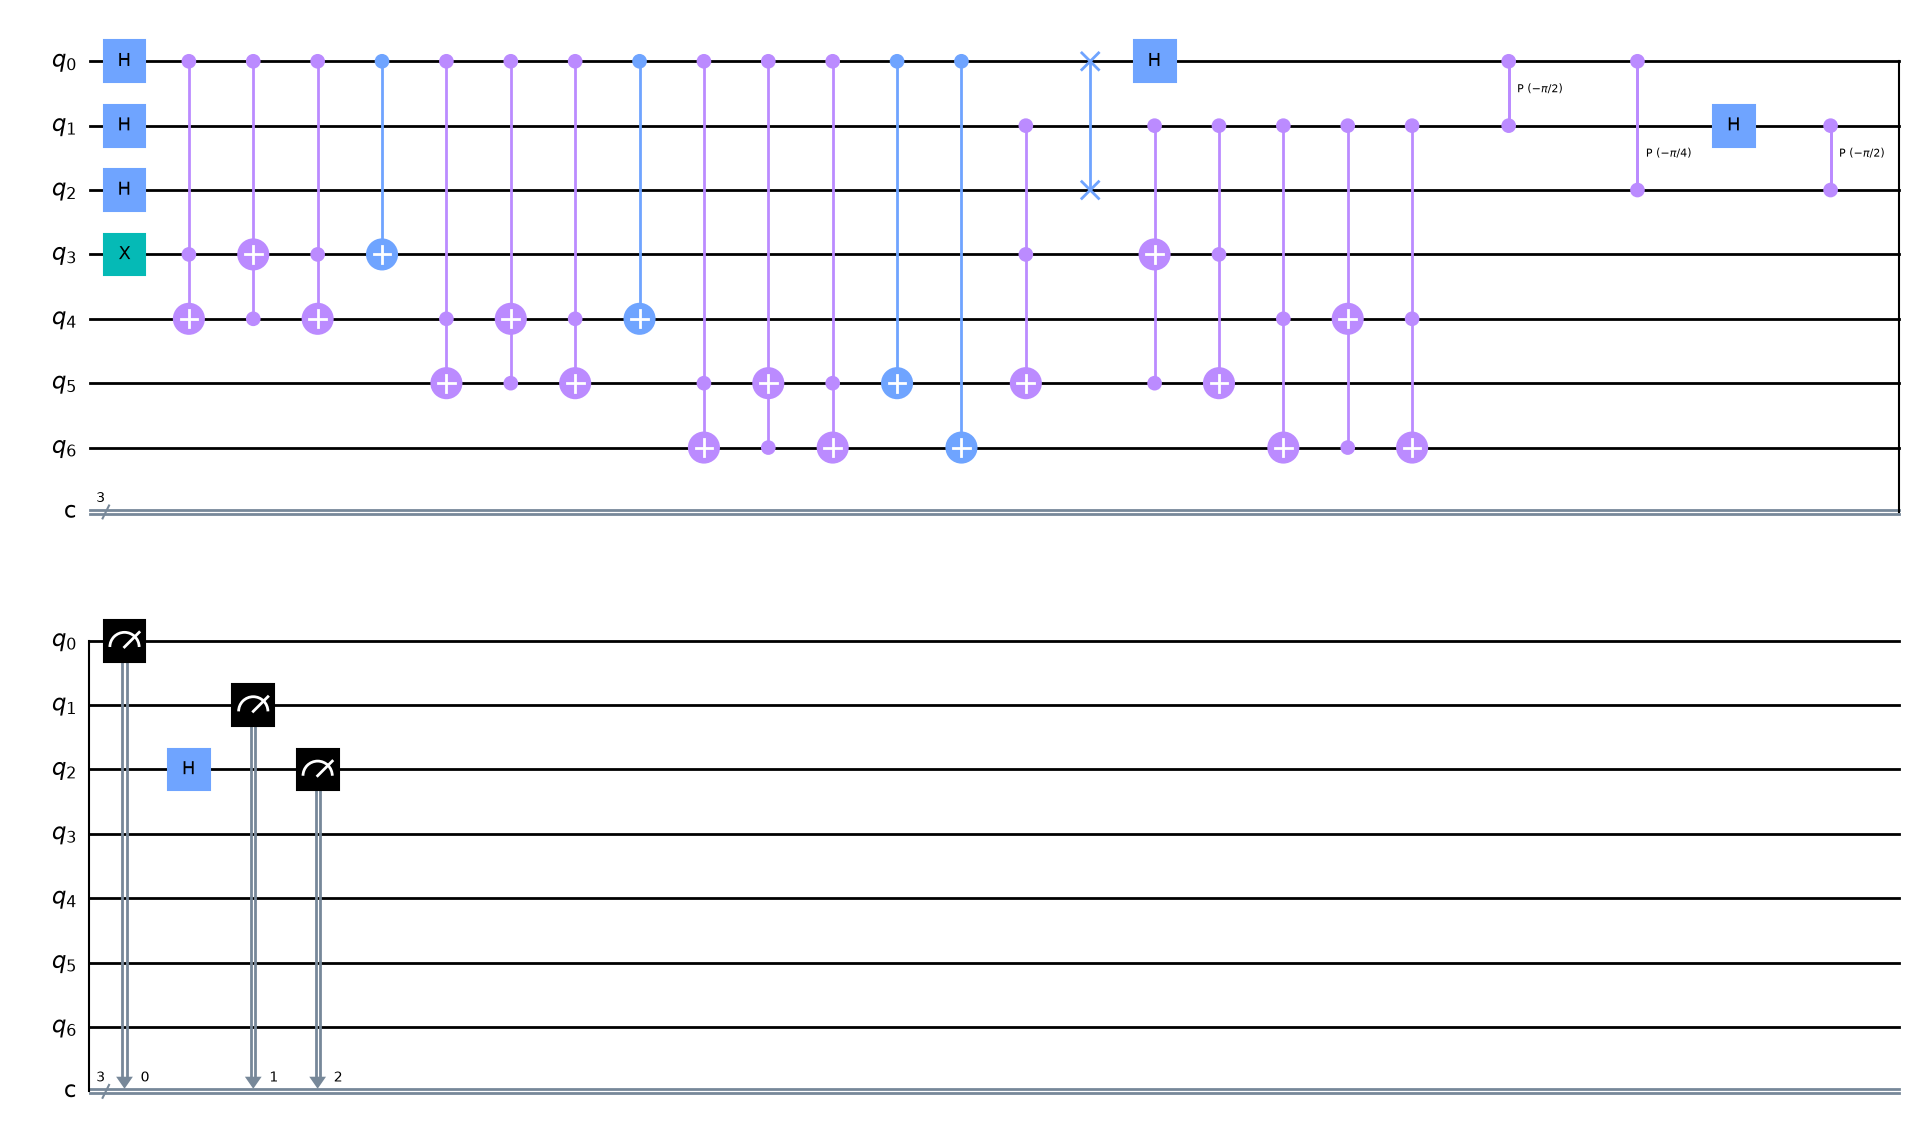

↑ the same circuit with 3 counting qubits, custom gates expanded: H on the counting register, X on the first work qubit, three controlled multiplications (Toffolis), then QFT† and the measurements


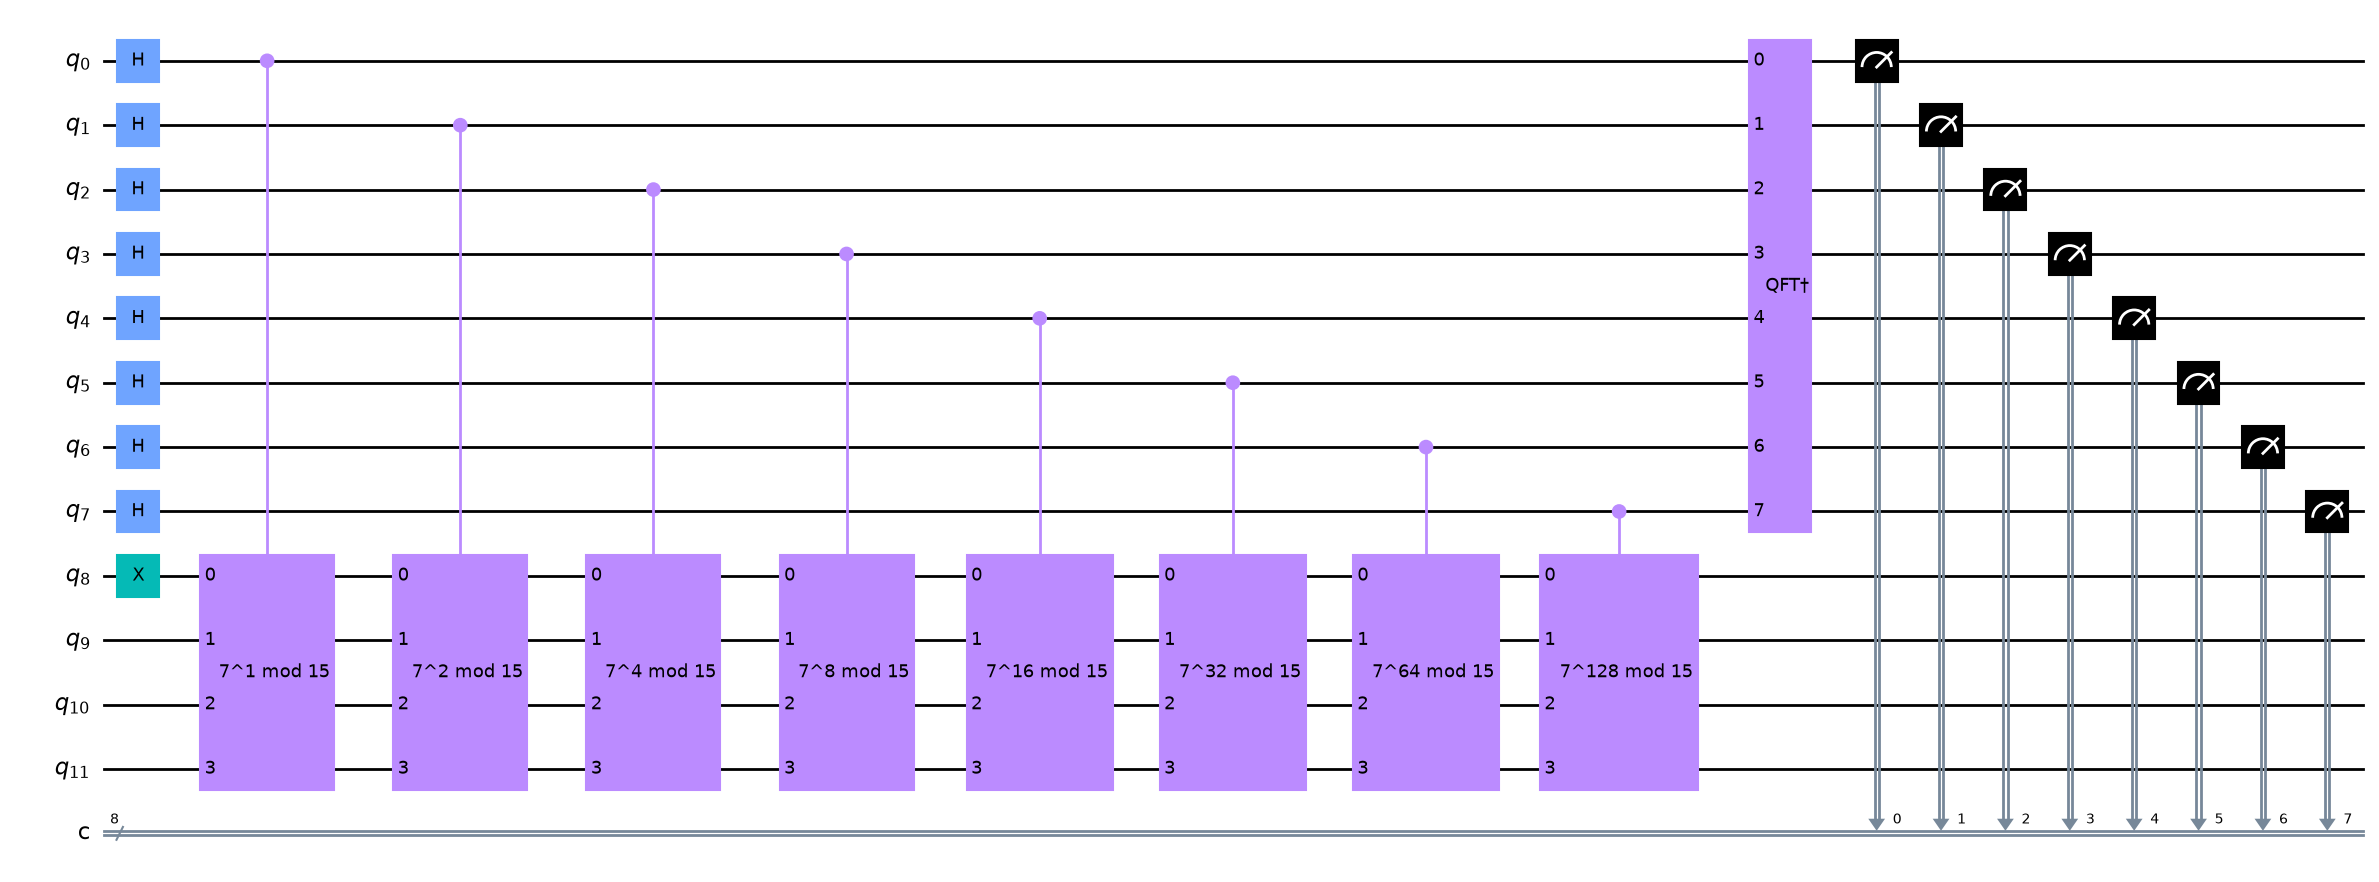

↑ the circuit we run: 8 counting qubits (top), 4 work qubits (bottom); each box is controlled-U^(2^q), the last box is QFT†


In [7]:
def build_order_finding_circuit(a, n_count=8):
    """QPE circuit for the order of a mod 15 with `n_count` counting qubits."""
    qc = QuantumCircuit(n_count + 4, n_count)   # QuantumCircuit(number_of_qubits, number_of_classical_bits)
    for q in range(n_count):          # counting register -> |+>
        qc.h(q)
    qc.x(n_count)                     # work register -> |1>  (qubit n_count is the first = least significant work qubit)
    for q in range(n_count):          # controlled-U^{2^q}, controlled by counting qubit q
        # qc.append(gate, qubits): the list names the qubits the gate acts on, control first
        qc.append(c_amod15(a, 2 ** q), [q] + [i + n_count for i in range(4)])
    qc.append(qft_dagger(n_count), range(n_count))   # inverse QFT on the counting register (a circuit can be appended like a gate)
    qc.measure(range(n_count), range(n_count))       # measure(qubits, classical_bits): qubit q -> bit q; the work register is not measured
    return qc

N_COUNT = 8
a = 7
qc = build_order_finding_circuit(a, N_COUNT)
print(f"{qc.num_qubits} qubits, {qc.num_clbits} classical bits, depth {qc.depth()}, {qc.size()} gates before transpilation")

small = build_order_finding_circuit(a, 3).decompose(gates_to_decompose=[f"c{a}^*", "QFT†"])   # expand only our custom gates (name wildcard *), keep H and X
display(draw(small, fold=28)); print("↑ the same circuit with 3 counting qubits, custom gates expanded: H on the counting register, X on the first work qubit, three controlled multiplications (Toffolis), then QFT† and the measurements")

display(draw(qc)); print(f"↑ the circuit we run: {N_COUNT} counting qubits (top), 4 work qubits (bottom); each box is controlled-U^(2^q), the last box is QFT†")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumCircuit(n_count + 4, n_count)` | counting register (qubits 0 … n_count−1) + 4-qubit work register; n_count classical bits for the result |
| `qc.h(q)`, `qc.x(n_count)` | \|+⟩ on every counting qubit; \|0001⟩ = \|1⟩ on the work register (qubit n_count is its least significant bit) |
| `qc.append(c_amod15(a, 2**q), [q] + [...])` | controlled-U^(2^q) with counting qubit q as control: the QPE pattern, higher qubits get higher powers |
| `qc.append(qft_dagger(n_count), range(n_count))` | a circuit appended like a gate: the inverse QFT turns the phase into a binary number in the counting register |
| `qc.measure(range(n_count), range(n_count))` | qubit q → classical bit q; the work register is left unmeasured |
| `qc.depth()`, `qc.size()`, `qc.num_qubits` | circuit statistics: depth = number of layers of gates that cannot run in parallel |
| `decompose(gates_to_decompose=[...])` | expand only the gates whose names match (wildcard `*`), so H and X stay readable; `fold=28` wraps the drawing after 28 columns |

</details>


Run it and look at the histogram of the counting register.

transpiled: 70 gates, depth 29, gate counts {'cp': 28, 'ccx': 15, 'h': 14, 'measure': 8, 'cx': 4, 'x': 1}


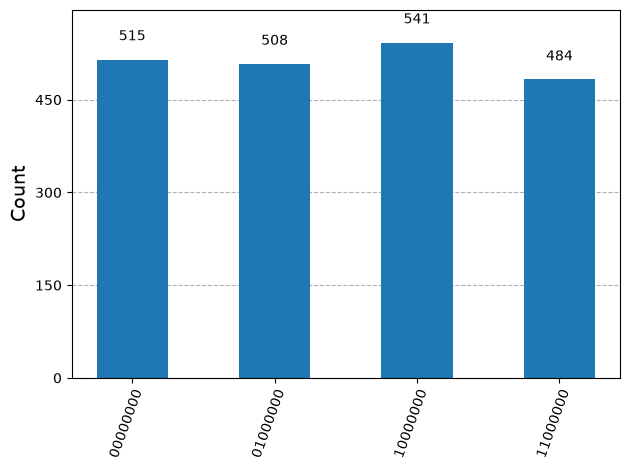

In [8]:
backend = AerSimulator()                                   # local ideal (noise-free) simulator; same .run interface as a real device
pm = generate_preset_pass_manager(optimization_level=3, backend=backend)   # the transpiler, configured for this backend
qc_isa = pm.run(qc)                                        # rewrite qc using only the gates the backend understands
print(f"transpiled: {qc_isa.size()} gates, depth {qc_isa.depth()}, gate counts {dict(qc_isa.count_ops())}")   # count_ops(): {gate name: count}
job = backend.run(qc_isa, shots=2048)                      # submit the circuit; shots = number of repetitions
counts = job.result().get_counts()                         # dict {'bitstring': how many shots gave it}

def run_circuit(circuit, shots=2048):
    """Transpile + run + counts in one call (used by the exercises at the end)."""
    return backend.run(pm.run(circuit), shots=shots).result().get_counts()

plot_histogram(counts)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `AerSimulator()` | a classical simulator with the same `run` interface as a real backend |
| `generate_preset_pass_manager(optimization_level=3, backend=...)` | the transpiler: unroll our custom gates into the backend's basis gates and optimise; level 3 = most aggressive |
| `backend.run(qc_isa, shots=2048)` | a job; `.result().get_counts()` waits for it and returns {bitstring: count} |
| `qc_isa.size()`, `.depth()`, `.count_ops()` | what actually runs: number of gates, depth, and the histogram of gate names (`cp` and `ccx` dominate) |
| `run_circuit(circuit, shots)` | the same three steps in one function, used by the exercises at the end |

</details>


The four tall peaks sit at register values $0, 64, 128, 192$ out of $2^8=256$, i.e. measured
phases $\phi = 0,\ \tfrac14,\ \tfrac12,\ \tfrac34$ — exactly the fractions $s/r$ with $r=4$.

In [9]:
rows, measured_phases = [], []
for output in counts:                            # iterating over a dict gives its keys: the measured bitstrings
    decimal = int(output, 2)                     # int(string, 2): read the string as a base-2 number
    phase = decimal / (2 ** N_COUNT)             # phi = (register value) / 2^n
    measured_phases.append(phase)
    rows.append([f"{output} (bin) = {decimal:>3} (dec)",       # :>3 = right-align in 3 characters
                 f"{decimal}/{2**N_COUNT} = {phase:.3f}"])     # :.3f = 3 decimal places
print(pd.DataFrame(rows, columns=["Register output", "Phase phi = s/r"]).to_string(index=False))   # pandas table


           Register output Phase phi = s/r
01000000 (bin) =  64 (dec)  64/256 = 0.250
00000000 (bin) =   0 (dec)   0/256 = 0.000
10000000 (bin) = 128 (dec) 128/256 = 0.500
11000000 (bin) = 192 (dec) 192/256 = 0.750


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `for output in counts` | iterating a dict yields its keys: the measured bitstrings, most significant counting qubit first |
| `int(output, 2)` | base-2 string → integer; dividing by 2^N_COUNT turns it into the phase φ ∈ [0, 1) |
| `f"{decimal:>3}"`, `f"{phase:.3f}"` | format specifications: width 3 right-aligned; 3 decimals |
| `pd.DataFrame(rows, columns=...)` | a table from a list of rows; `.to_string(index=False)` prints it without row numbers |

</details>


## 5. From phase to order: continued fractions

QPE hands us $\phi \approx s/r$ as a finite-precision binary fraction. We need the *actual*
rational $s/r$ in lowest terms. The **continued fraction expansion** of $\phi$ gives the best
rational approximations with bounded denominator; the theory of QPE guarantees that if the
phase is estimated to enough bits, the convergent with denominator $< N$ is exactly $s/r$.

Python's `fractions.Fraction(...).limit_denominator(N)` does precisely this. Watch why the
`limit_denominator` step is essential — a raw float becomes an ugly exact fraction:

In [10]:
print("raw            :", Fraction(0.75))                       # Fraction(float) = the exact binary value, often ugly
print("limited (<15)  :", Fraction(0.75).limit_denominator(15))  # closest fraction with denominator <= 15 -> 3/4

def best_rational(phi, max_den):
    """Best rational approx p/q to phi with q <= max_den, via continued fractions."""
    f = Fraction(phi).limit_denominator(max_den)   # Python's implementation of the continued-fraction algorithm
    return f.numerator, f.denominator             # s and r

rows = []
for phase in sorted(set(measured_phases)):        # set() removes duplicates, sorted() orders them
    s, r = best_rational(phase, 15 - 1)           # the order must be < N = 15 (the modulus of the circuit)
    rows.append([f"{phase:.3f}", f"{s}/{r}", r])
print(pd.DataFrame(rows, columns=["Phase", "s/r", "Guess for r"]).to_string(index=False))


raw            : 3/4
limited (<15)  : 3/4
Phase s/r  Guess for r
0.000 0/1            1
0.250 1/4            4
0.500 1/2            2
0.750 3/4            4


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `Fraction(0.75)` | the exact value of the binary float as a fraction; for a phase such as 0.727 that would be a 50-digit fraction |
| `.limit_denominator(14)` | the closest fraction with denominator ≤ 14: the continued-fraction convergent that QPE theory promises is s/r |
| `sorted(set(measured_phases))` | the distinct phases in increasing order |
| `best_rational(phi, max_den)` | returns `(numerator, denominator)`: s and the candidate order r |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The continued fraction of a measured phase.** Divide like Euclid and keep the quotients. For $\phi = 0.75 = 3/4$:

$$\tfrac34 = 0 + \tfrac{1}{4/3} = 0 + \cfrac{1}{1 + \tfrac{1}{3}} = [0;\,1,\,3], \qquad \text{convergents } \tfrac01,\ \tfrac11,\ \tfrac34 .$$

The last convergent with denominator $< 15$ is $3/4$: $r = 4$ ✓.

**A noisy outcome.** On a real device the register may read $186$, i.e. $\phi = 186/256 = 93/128$. Euclid on $(128, 93)$ gives the quotients $128 = 1\cdot 93 + 35,\ 93 = 2\cdot 35 + 23,\ 35 = 1\cdot 23 + 12,\ 23 = 1\cdot 12 + 11,\ 12 = 1\cdot 11 + 1,\ 11 = 11\cdot 1$, so

$$\tfrac{93}{128} = [0;\,1,\,2,\,1,\,1,\,1,\,11], \qquad \text{convergents } \tfrac01,\ \tfrac11,\ \tfrac23,\ \tfrac34,\ \tfrac57,\ \tfrac8{11},\ \tfrac{93}{128} .$$

With denominators capped at $14$ the best approximation is $8/11$ ($|0.7266 - 0.7273| < 0.001$), so the candidate is $r = 11$: odd, and $7^{11} \not\equiv 1 \pmod{15}$. `factors_from_order` returns `[]` and the loop of Section 6 tries again — this is how wrong samples are rejected without ever knowing they were wrong.

**Why the cap.** Each convergent $p_k/q_k$ is the best rational approximation with denominator $\le q_k$, and $|\phi - s/r| \le 1/2^{n+1}$ for an $n$-bit phase. If $2^{n} \ge N^2$ (here $256 \ge 225$ ✓) the theory of continued fractions guarantees that $s/r$ itself is one of the convergents — the only one with $q_k < N$ that lies within $1/(2q_k^2)$ of $\phi$. That is the precision argument behind `N_COUNT = 8` for $N = 15$.

</details>


Phases $\tfrac14$ and $\tfrac34$ both yield $r=4$ (correct). Phase $\tfrac12$ gives the
*factor* $r=2$ of the true order (here $s=1,r=2$ shares no useful split), and phase $0$ (the
$s=0$ outcome) is useless. This is why Shor's algorithm is **probabilistic**: some measurements
fail, so we repeat until the recovered $r$ actually works.

## 6. A complete, robust `shor_factor(N)`

Now we assemble everything: classical reductions $\to$ random $a$ $\to$ quantum order finding
$\to$ continued fractions $\to$ `factors_from_order`, looping until a non-trivial factor appears.
(The quantum step uses the $N=15$ operator, so `shor_factor` is specialised to $N=15$ here — the
same control flow is exactly what a general implementation uses once a general modular-exponentiation
circuit is plugged in; see Section 8.)

In [11]:
def qpe_order_15(a, n_count=8):
    """One QPE shot -> measured phase for the order of a mod 15."""
    qc = build_order_finding_circuit(a, n_count)
    backend = AerSimulator()
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    job = backend.run(pm.run(qc), shots=1, memory=True)   # memory=True keeps the result of each individual shot
    reading = job.result().get_memory()[0]                # the bitstring of our single shot
    return int(reading, 2) / (2 ** n_count)


def shor_factor(N=15, n_count=8, max_attempts=20, seed=None, verbose=True):
    """Factor N (specialised to N=15 operator) via Shor order finding. Returns (p, q) or None."""
    rng = np.random.default_rng(seed)         # random generator; a fixed seed makes the run reproducible

    # --- classical shortcuts ---
    if N % 2 == 0:
        return 2, N // 2
    pk = is_perfect_power(N)
    if pk:                                    # a tuple counts as True, None counts as False
        return pk[0], N // pk[0]

    valid_a = [2, 4, 7, 8, 11, 13]            # a coprime to 15 that c_amod15 supports
    for attempt in range(1, max_attempts + 1):
        a = int(rng.choice(valid_a))          # pick a random element of the list
        g = gcd(a, N)
        if g > 1:                             # lucky: a already shares a factor
            if verbose: print(f"attempt {attempt}: gcd({a},{N})={g} (lucky hit)")
            return g, N // g
        phase = qpe_order_15(a, n_count)      # <-- the only quantum step
        s, r = best_rational(phase, N - 1)    # continued fractions: phase -> s/r
        facs = factors_from_order(a, r, N)    # order -> factors (may fail: empty list)
        if verbose:
            print(f"attempt {attempt}: a={a}, phi={phase:.3f}, r={r}, factors={facs}")
        if facs:                              # a non-empty list counts as True
            p = facs[0]
            return p, N // p
    return None                               # gave up after max_attempts

print("Factoring 15 with Shor's algorithm:")
print("result:", shor_factor(15, seed=2))


Factoring 15 with Shor's algorithm:


attempt 1: a=13, phi=0.250, r=4, factors=[3, 5]
result: (3, 5)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `np.random.default_rng(seed)` | NumPy's random generator; the same seed reproduces the same sequence of bases a |
| `rng.choice(valid_a)` | a random element of the list; `int(...)` because NumPy returns its own integer type |
| `if pk:`, `if facs:` | Python truthiness: `None` and `[]` count as False, a tuple or a non-empty list as True |
| `qpe_order_15(a, n_count)` | one shot of the QPE circuit = one random sample of s/r, read as a raw bitstring rather than a histogram |
| `best_rational` → `factors_from_order` | the two classical post-processing steps; an empty list means 'bad sample, draw a new a' |
| `return p, N // p` | the function returns a tuple; the caller unpacks it with `p, q = ...` |

</details>


## 7. Closing the loop: breaking a (toy) RSA key

In the lesson, RSA security rests on the hardness of factoring the modulus $N=pq$. Here we build a
*tiny* RSA key on $N=15$, then use the factors Shor recovered to reconstruct the **private key** and
decrypt — the exact attack Shor enables (just at a scale small enough to simulate).

In [12]:
def egcd(a, b):
    """Extended Euclid: returns (g, x, y) with g = gcd(a, b) and a*x + b*y = g (Bézout)."""
    if b == 0: return (a, 1, 0)
    g, x, y = egcd(b, a % b)                  # recursion: the function calls itself on smaller numbers
    return (g, y, x - (a // b) * y)

def modinv(e, m):
    """Inverse of e modulo m: the d with e*d = 1 (mod m)."""
    g, x, _ = egcd(e % m, m)                  # '_' = a returned value we do not need
    if g != 1: raise ValueError("no inverse")
    return x % m

# --- toy RSA public key (modulus deliberately factorable) ---
N_rsa = 15
e = 7                       # public exponent, must be coprime to phi(N)
message = 2
cipher = pow(message, e, N_rsa)              # encryption: c = m^e mod N
print(f"public key (N={N_rsa}, e={e}); ciphertext of m={message} is c={cipher}")

# --- attacker runs Shor to factor N, then rebuilds the private key ---
p, q = shor_factor(N_rsa, seed=2, verbose=False)   # tuple unpacking of the returned (p, q)
phi = (p - 1) * (q - 1)
d = modinv(e, phi)                           # private exponent d = e^{-1} mod phi(N)
recovered = pow(cipher, d, N_rsa)            # decryption: m = c^d mod N
print(f"Shor found p={p}, q={q}  ->  phi={phi}, private key d={d}")
print(f"decrypted message = {recovered}   (attack {'succeeded' if recovered == message else 'failed'})")


public key (N=15, e=7); ciphertext of m=2 is c=8


Shor found p=3, q=5  ->  phi=8, private key d=7
decrypted message = 2   (attack succeeded)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `egcd(a, b)` | the extended Euclidean algorithm, recursively: the Bézout coefficients x, y with a·x + b·y = gcd(a, b) |
| `g, x, _ = egcd(...)` | tuple unpacking; `_` is the conventional name for a value we ignore |
| `pow(message, e, N_rsa)`, `pow(cipher, d, N_rsa)` | encryption and decryption are the same operation with different exponents |
| `x % m` | Python's `%` returns a non-negative result for positive m, so a negative Bézout coefficient becomes a valid inverse |
| `'succeeded' if ... else 'failed'` | a conditional expression inside an f-string |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The toy key by hand.** $N = 15 = 3\cdot 5$, $\varphi(N) = 2\cdot 4 = 8$, $e = 7$ ($\gcd(7, 8) = 1$ ✓).

*Private exponent.* $d = 7^{-1} \bmod 8$: $7\cdot 7 = 49 = 6\cdot 8 + 1$, so $d = 7$ (with $e = d$ this toy key is its own inverse — one more reason real keys are not 4 bits long).

*Encryption of m = 2.* $c = 2^{7} \bmod 15 = 128 - 8\cdot 15 = 8$ ✓ (the cell prints `c=8`).

*Decryption.* $8^{7} \bmod 15$ by repeated squaring: $8^{2} = 64 \equiv 4$, $8^{4} \equiv 4^{2} = 16 \equiv 1$, so $8^{7} = 8^{4}\cdot 8^{2}\cdot 8 \equiv 1\cdot 4\cdot 8 = 32 \equiv 2$ ✓.

*Why it works.* $ed = 49 = 1 + 6\cdot\varphi(N)$, and Euler's theorem gives $m^{\varphi(N)} \equiv 1$ for $\gcd(m, N) = 1$, hence $c^{d} = m^{ed} = m\,(m^{8})^{6} \equiv m$. The attacker needed only $p$ and $q$ to get $\varphi(N)$ — exactly what Shor delivered.

</details>


## 8. The real bottleneck: modular exponentiation, and a resource reality check

The controlled-$U^{2^q}$ gates are the expensive part. We *cannot* build $U^{2^q}$ by repeating
$U$ a total of $2^q$ times — that is exponential. The trick is that

$$ U^{2^q}|y\rangle = |a^{2^q} y \bmod N\rangle, \qquad a^{2^{q}} \bmod N $$

can be precomputed **classically** by *repeated squaring* in $O(q)$ multiplications, and the modular
multiplier can be realised as a reversible circuit. A clean beginner-friendly construction
(Beauregard) factors an $n$-bit $N$ with only $2n+3$ qubits.

In [13]:
def a2jmodN(a, j, N):
    """Compute a^{2^j} mod N by repeated squaring (classical, O(j) multiplications)."""
    for _ in range(j):                 # '_' = loop variable we do not use
        a = (a * a) % N                # square and reduce mod N at every step: numbers never grow
    return a

print("7^(2^2) mod 53 =", a2jmodN(7, 2, 53))      # fast even for huge exponents
print("7^(2^2049) mod 53 =", a2jmodN(7, 2049, 53))


7^(2^2) mod 53 = 16
7^(2^2049) mod 53 = 47


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `for _ in range(j): a = (a * a) % N` | repeated squaring: j squarings give a^(2^j); reducing mod N at every step keeps every intermediate number below N² |
| `a2jmodN(7, 2049, 53)` | 2049 squarings, instantaneous; the number 7^(2^2049) itself would have about 10^616 digits |

</details>


**Why RSA-2048 is still safe today.** Shor's algorithm is *polynomial* — $O((\log N)^3)$ gate
operations with $O(\log N)$ logical qubits — so asymptotically RSA is broken. But the constants and
the **error-correction overhead** are brutal:

* Factoring a 2048-bit modulus needs on the order of a few **thousand logical qubits** and billions
  of fault-tolerant gates (e.g. Gidney–Ekerå estimate: ~20 million *noisy* physical qubits running
  for hours, under plausible assumptions).
* Today's devices — Garnet (20 qubits), Emerald (54 qubits), and the largest superconducting chips
  (hundreds of physical qubits) — are **nowhere near** the fault-tolerant scale required.

So the demonstration here factors $15$ (and with a general modular-exponentiation circuit, numbers
like $21$, $35$), not $2048$-bit keys. The threat is real but *future*, which is exactly why the
world is migrating to **post-quantum cryptography** (lattice-based schemes such as ML-KEM/Kyber).
This mirrors the closing section of the lesson.

## 9. 🔬 In-depth analysis

1. **Other bases.** Re-run the order-finding circuit with $a = 2, 8, 11, 13$. Turn every measured phase into a candidate $r$ with `best_rational` and keep the ones with $a^r \equiv 1 \pmod{15}$. Which orders do you get, and which values of $a$ give an *even* order usable for factoring?
2. **Precision.** Change `N_COUNT` to 4 and then to 10. How does the sharpness of the histogram peaks — and the reliability of the recovered $r$ — change? Measure the fraction of shots that land exactly on the four ideal outcomes $k\cdot 2^{N_{\rm COUNT}}/4$ and relate it to the QPE precision argument of the box in Section 5.
3. **Success probability.** Run the factoring loop 20 times with different seeds and record the attempt at which each run succeeds. Estimate the empirical success probability per attempt (for a geometric law it is $1/\overline{\text{attempts}}$) and compare it with the $\ge 1/2$ bound of Section 2 — which concerns the order only: the phase $\to$ order step can fail too ($s = 0$, or $s$ sharing a factor with $r$).

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [14]:
# 🔬 In-depth analysis — your code here



(1) a =  2: candidates [1, 2, 4] -> r = 4 (even: usable), factors [3, 5]


(1) a =  8: candidates [1, 2, 4] -> r = 4 (even: usable), factors [3, 5]
(1) a = 11: candidates [1, 2] -> r = 2 (even: usable), factors [3, 5]


(1) a = 13: candidates [1, 2, 4] -> r = 4 (even: usable), factors [3, 5]
(2) N_COUNT =  4:    16 possible outcomes, 100.0% of the shots exactly on the four ideal peaks


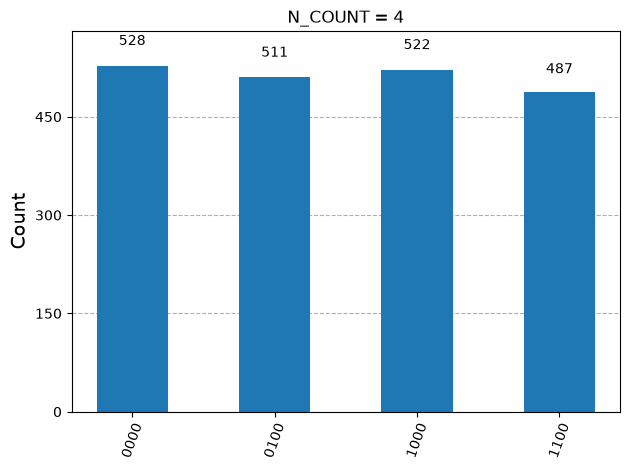

(2) N_COUNT = 10:  1024 possible outcomes, 100.0% of the shots exactly on the four ideal peaks


(3) 20 successful runs; attempts needed: [2, 4, 3, 1, 2, 1, 2, 4, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 3, 3]
    mean 1.95 attempts -> empirical success probability per attempt ≈ 0.51


In [15]:
# Reference solution
# (1) orders for the other bases: run the QPE circuit, turn every measured phase into a candidate r, keep those that work
for a_ in (2, 8, 11, 13):
    cnt = run_circuit(build_order_finding_circuit(a_, N_COUNT), shots=512)
    cands = {best_rational(int(k, 2) / 2 ** N_COUNT, 14)[1] for k in cnt}            # set comprehension: candidate orders from all phases
    good = sorted(r_ for r_ in cands if r_ > 1 and pow(a_, r_, 15) == 1)              # the candidates that really satisfy a^r = 1 mod 15
    r_ = min(good) if good else None                                                  # the order is the smallest of them
    print(f"(1) a = {a_:2d}: candidates {sorted(cands)} -> r = {r_} "
          f"({'even: usable' if r_ and r_ % 2 == 0 else 'odd or none: retry'}), factors {factors_from_order(a_, r_, 15) if r_ else []}")

# (2) precision: fewer / more counting qubits
for n_ in (4, 10):
    cnt = run_circuit(build_order_finding_circuit(7, n_), shots=2048)
    peaks = {k * 2 ** n_ // 4 for k in range(4)}                                        # the ideal outcomes: phases 0, 1/4, 1/2, 3/4
    on_peak = sum(v for k, v in cnt.items() if int(k, 2) in peaks) / sum(cnt.values())  # fraction of shots exactly on them
    print(f"(2) N_COUNT = {n_:2d}: {2 ** n_:5d} possible outcomes, {on_peak:.1%} of the shots exactly on the four ideal peaks")
    if n_ <= 8: display(plot_histogram(cnt, title=f"N_COUNT = {n_}"))                 # 1024 bars would be unreadable: print only for n = 10

# (3) success probability per attempt: the loop of shor_factor, instrumented
rng_x = np.random.default_rng(123); attempts_needed = []
for run_ in range(20):
    for attempt in range(1, 21):
        a_ = int(rng_x.choice([2, 4, 7, 8, 11, 13]))
        s_, r_ = best_rational(qpe_order_15(a_, N_COUNT), 14)                           # one quantum shot -> candidate order
        if factors_from_order(a_, r_, 15):                                              # a non-trivial factor: this run is over
            attempts_needed.append(attempt); break
mean_att = np.mean(attempts_needed)
print(f"(3) {len(attempts_needed)} successful runs; attempts needed: {attempts_needed}")
print(f"    mean {mean_att:.2f} attempts -> empirical success probability per attempt ≈ {1 / mean_att:.2f}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `{best_rational(...)[1] for k in cnt}` | a set comprehension over the measured bitstrings: every phase becomes a candidate order, duplicates vanish |
| `pow(a_, r_, 15) == 1` | the check that distinguishes the true order from an artefact of the rounding |
| `{k * 2**n_ // 4 for k in range(4)}` | the four ideal register values for r = 4; with n counting qubits they are 0, 2ⁿ/4, 2ⁿ/2, 3·2ⁿ/4 |
| `sum(...) / sum(cnt.values())` | a fraction of shots: the sharper the peaks, the closer to 1 (noise and the finite precision of QPE spread it) |
| `for ... : ... break` | the inner loop ends at the first success; the attempt number is what we record |
| `np.mean(attempts_needed)` | for a geometric law with success probability p the mean number of attempts is 1/p |

</details>


## 10. References

1. P. W. Shor, *Polynomial-Time Algorithms for Prime Factorization and Discrete Logarithms on a
   Quantum Computer*, SIAM J. Comput. **26** (1997) 1484. [arXiv:quant-ph/9508027]
2. S. Beauregard, *Circuit for Shor's algorithm using $2n+3$ qubits*, [arXiv:quant-ph/0205095].
3. M. Nielsen and I. Chuang, *Quantum Computation and Quantum Information*, Cambridge Univ. Press
   (2000), Ch. 5 and p. 633.
4. C. Gidney and M. Ekerå, *How to factor 2048 bit RSA integers in 8 hours using 20 million noisy
   qubits*, Quantum **5** (2021) 433. [arXiv:1905.09749]
